<a href="https://colab.research.google.com/github/Fametwitter160/Efficient-LoRA-Based-Fine-Tuning-of-LLM-for-Multi-Class-Cybersecurity-Threat-Classification/blob/main/DL_model1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U torchao
!pip install -q transformers peft accelerate sentencepiece

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

GPU available: False
Running on CPU


In [ ]:
import random
import pandas as pd

SEED = 42
random.seed(SEED)

TEMPLATES = {
    "intrusion": [
        "Repeated failed login attempts were detected from {src} against the admin account.",
        "An unusual SSH connection was observed from {src} to the internal server.",
        "Multiple authentication failures suggest an attempted unauthorized access.",
        "The security log reports a port scan followed by suspicious access attempts.",
        "A remote host generated abnormal connection attempts across several internal ports.",
        "Unauthorized access attempts were detected on the organization's server.",
        "Suspicious network scanning activity was detected from an external host.",
        "Multiple connection attempts were recorded against restricted services."
    ],

    "phishing": [
        "The message asks the employee to verify the account through an unfamiliar link.",
        "An email claims the mailbox will be disabled unless the recipient confirms credentials.",
        "The sender requests an urgent password reset using a suspicious website.",
        "The message contains a deceptive login link and creates pressure to act immediately.",
        "A fake security notification asks the user to enter account information.",
        "The email requests confidential information through an unknown website.",
        "A suspicious message asks the recipient to click a verification link.",
        "The sender claims immediate action is required to prevent account suspension."
    ],

    "malware": [
        "The endpoint detected a suspicious executable attempting to modify system files.",
        "An unknown program created unusual startup entries and triggered antivirus alerts.",
        "The workstation reported behavior consistent with a malicious software infection.",
        "A downloaded file was flagged because it attempted unauthorized process execution.",
        "The security agent isolated a suspicious binary after detecting abnormal file activity.",
        "A malicious executable attempted to access protected system resources.",
        "Antivirus software detected suspicious software running on the workstation.",
        "A downloaded application showed behavior associated with malware."
    ],

    "normal": [
        "The employee successfully logged in using the approved corporate network.",
        "The scheduled backup completed successfully with no security alerts.",
        "The system update finished normally and the security checks passed.",
        "A routine application access event was recorded from the employee workstation.",
        "The server completed its scheduled maintenance without any detected anomalies.",
        "The employee accessed an approved application from the company network.",
        "A routine login was recorded without any security warnings.",
        "The scheduled system maintenance completed successfully."
    ]
}

SOURCES = [
    "10.0.0.15",
    "10.0.0.21",
    "172.16.2.14",
    "192.168.1.44",
    "10.20.3.8"
]

rows = []

for label, templates in TEMPLATES.items():

    for i in range(1200):

        text = random.choice(templates).format(
            src=random.choice(SOURCES)
        )

        if i % 4 == 0:
            text += " Security monitoring generated an alert."

        elif i % 4 == 1:
            text += " The event was recorded in the security log."

        elif i % 4 == 2:
            text += " The activity was reviewed by the monitoring system."

        else:
            text += " The security event was analyzed by the monitoring team."

        rows.append((text, label))

random.shuffle(rows)

df = pd.DataFrame(
    rows,
    columns=["text", "label"]
)

df.to_csv("dataset.csv", index=False)

print("Dataset created successfully.")
print("Total samples:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nFirst 5 samples:")
print(df.head())

Dataset created successfully.
Total samples: 4800

Class distribution:
label
normal       1200
phishing     1200
intrusion    1200
malware      1200
Name: count, dtype: int64

First 5 samples:
                                                text      label
0  The server completed its scheduled maintenance...     normal
1  The email requests confidential information th...   phishing
2  The email requests confidential information th...   phishing
3  Repeated failed login attempts were detected f...  intrusion
4  A malicious executable attempted to access pro...    malware


In [ ]:
import pandas as pd

df = pd.read_csv("dataset.csv")

print(df.shape)
display(df.head())

print("\nClass Distribution:")
print(df["label"].value_counts())

(4800, 2)


,text,label
0,The server completed its scheduled maintenance...,normal
1,The email requests confidential information th...,phishing
2,The email requests confidential information th...,phishing
3,Repeated failed login attempts were detected f...,intrusion
4,A malicious executable attempted to access pro...,malware



Class Distribution:
label
normal       1200
phishing     1200
intrusion    1200
malware      1200
Name: count, dtype: int64


In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from transformers import (
    DistilBertTokenizerFast,
    DistilBertModel,
    get_linear_schedule_with_warmup
)

from peft import (
    LoraConfig,
    TaskType,
    get_peft_model
)

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "distilbert-base-uncased"

# Optimized for faster CPU training
MAX_LEN = 64
BATCH_SIZE = 16
EPOCHS = 1
LEARNING_RATE = 2e-4
WARMUP_STEPS = 50

NUM_CLASSES = 4

LABELS = [
    "intrusion",
    "phishing",
    "malware",
    "normal"
]

LABEL2ID = {
    label: i
    for i, label in enumerate(LABELS)
}

# ============================================================
# 2. DATASET CLASS
# ============================================================

class CyberThreatDataset(Dataset):

    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN
        )
        self.labels = [
            LABEL2ID[label]
            for label in labels
        ]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: torch.tensor(
                value[index],
                dtype=torch.long
            )
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )
        return item

# ============================================================
# 3. DISTILBERT + LoRA MODEL
# ============================================================

class CyberThreatModel(nn.Module):

    def __init__(self):
        super().__init__()
        base_model = DistilBertModel.from_pretrained(
            MODEL_NAME
        )
        lora_config = LoraConfig(
            task_type=TaskType.FEATURE_EXTRACTION,
            r=8,
            lora_alpha=16,
            lora_dropout=0.1,
            target_modules=[
                "q_lin",
                "v_lin"
            ],
            bias="none"
        )
        self.encoder = get_peft_model(
            base_model,
            lora_config
        )
        self.classifier = nn.Linear(
            768,
            NUM_CLASSES
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        labels=None
    ):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        cls_vector = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_vector)
        loss = None
        if labels is not None:
            loss_function = nn.CrossEntropyLoss()
            loss = loss_function(
                logits,
                labels
            )
        return loss, logits

# ============================================================
# 4. PARAMETER COUNT
# ============================================================

def count_parameters(model):
    total = sum(
        parameter.numel()
        for parameter in model.parameters()
    )
    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
    percentage = (
        100 * trainable / total
    )
    return total, trainable, percentage

# ============================================================
# 5. EVALUATION
# ============================================================

def evaluate(model, dataloader, device):
    model.eval()
    losses = []
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for batch in dataloader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }
            loss, logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            losses.append(loss.item())
            predictions = torch.argmax(logits, dim=1)
            true_labels.extend(
                batch["labels"].cpu().tolist()
            )
            predicted_labels.extend(
                predictions.cpu().tolist()
            )

    average_loss = np.mean(losses)
    accuracy = accuracy_score(true_labels, predicted_labels)
    precision = precision_score(true_labels, predicted_labels, average="macro", zero_division=0)
    recall = recall_score(true_labels, predicted_labels, average="macro", zero_division=0)
    f1 = f1_score(true_labels, predicted_labels, average="macro", zero_division=0)
    cm = confusion_matrix(true_labels, predicted_labels)

    return (
        average_loss,
        accuracy,
        precision,
        recall,
        f1,
        cm,
        true_labels,
        predicted_labels
    )

# ============================================================
# 6. MAIN TRAINING
# ============================================================

def main():
    print("=" * 60)
    print("DISTILBERT + LoRA CYBERSECURITY CLASSIFICATION")
    print("=" * 60)

    if not os.path.exists("dataset.csv"):
        raise FileNotFoundError(
            "dataset.csv not found."
        )

    df = pd.read_csv("dataset.csv")

    # Downsample slightly to allow fast execution on CPU
    df = df.groupby("label").sample(n=200, random_state=SEED).reset_index(drop=True)

    print("\nDownsampled Dataset size for fast CPU run:", len(df))

    train_df, temp_df = train_test_split(
        df,
        test_size=0.20,
        stratify=df["label"],
        random_state=SEED
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label"],
        random_state=SEED
    )

    print("\nData split:")
    print("Training:", len(train_df))
    print("Validation:", len(val_df))
    print("Testing:", len(test_df))

    print("\nLoading tokenizer...")
    tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

    train_dataset = CyberThreatDataset(train_df["text"], train_df["label"], tokenizer)
    val_dataset = CyberThreatDataset(val_df["text"], val_df["label"], tokenizer)
    test_dataset = CyberThreatDataset(test_df["text"], test_df["label"], tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("\nDevice:", device)

    print("\nLoading DistilBERT + LoRA...")
    model = CyberThreatModel().to(device)

    total_params, trainable_params, percentage = count_parameters(model)
    print("\nModel Parameters")
    print("-" * 40)
    print("Total parameters:", f"{total_params:,}")
    print("Trainable parameters:", f"{trainable_params:,}")
    print("Trainable percentage:", f"{percentage:.3f}%")

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE
    )

    total_steps = EPOCHS * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=WARMUP_STEPS,
        num_training_steps=total_steps
    )

    history = []

    print("\nStarting training...")
    print("=" * 60)

    for epoch in range(EPOCHS):
        model.train()
        training_losses = []

        for batch in train_loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            optimizer.zero_grad()
            loss, logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            loss.backward()
            optimizer.step()
            scheduler.step()
            training_losses.append(loss.item())

        train_loss = np.mean(training_losses)
        val_loss, val_accuracy, val_precision, val_recall, val_f1, _, _, _ = evaluate(
            model, val_loader, device
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_precision": val_precision,
            "val_recall": val_recall,
            "val_f1": val_f1
        })

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        print(f"Train Loss : {train_loss:.4f}")
        print(f"Val Loss   : {val_loss:.4f}")
        print(f"Val Accuracy : {val_accuracy:.4f}")
        print(f"Val Macro F1 : {val_f1:.4f}")

    print("\n")
    print("=" * 60)
    print("FINAL TEST RESULTS")
    print("=" * 60)

    test_loss, test_accuracy, test_precision, test_recall, test_f1, cm, true_labels, predicted_labels = evaluate(
        model, test_loader, device
    )

    print(f"\nTest Loss      : {test_loss:.4f}")
    print(f"Accuracy       : {test_accuracy:.4f}")
    print(f"Precision      : {test_precision:.4f}")
    print(f"Recall         : {test_recall:.4f}")
    print(f"Macro F1       : {test_f1:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(true_labels, predicted_labels, target_names=LABELS, zero_division=0))

    os.makedirs("local_model", exist_ok=True)
    model.encoder.save_pretrained("local_model")
    tokenizer.save_pretrained("local_model")
    torch.save(model.classifier.state_dict(), "local_model/classifier.pt")

    with open("local_model/labels.json", "w") as file:
        json.dump({"labels": LABELS}, file, indent=4)

    results = {
        "dataset_size": len(df),
        "train_size": len(train_df),
        "validation_size": len(val_df),
        "test_size": len(test_df),
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "max_sequence_length": MAX_LEN,
        "lora_rank": 8,
        "lora_alpha": 16,
        "lora_dropout": 0.1,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "trainable_percentage": percentage,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_precision": test_precision,
        "test_recall": test_recall,
        "test_macro_f1": test_f1,
        "confusion_matrix": cm.tolist(),
        "history": history
    }

    with open("training_results.json", "w") as file:
        json.dump(results, file, indent=4)

    print("\nModel saved to: local_model/")
    print("Results saved to: training_results.json")
    print("Training completed successfully.")

if __name__ == "__main__":
    main()

DISTILBERT + LoRA CYBERSECURITY CLASSIFICATION

Downsampled Dataset size for fast CPU run: 800

Data split:
Training: 640
Validation: 80
Testing: 80

Loading tokenizer...

Device: cpu

Loading DistilBERT + LoRA...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Model Parameters
----------------------------------------
Total parameters: 66,513,412
Trainable parameters: 150,532
Trainable percentage: 0.226%

Starting training...

Epoch 1/1
Train Loss : 1.3680
Val Loss   : 1.2992
Val Accuracy : 0.7375
Val Macro F1 : 0.7343


FINAL TEST RESULTS

Test Loss      : 1.3113
Accuracy       : 0.7500
Precision      : 0.7524
Recall         : 0.7500
Macro F1       : 0.7444

Confusion Matrix:
[[13  3  1  3]
 [ 0 16  4  0]
 [ 0  1 19  0]
 [ 5  3  0 12]]

Classification Report:
              precision    recall  f1-score   support

   intrusion       0.72      0.65      0.68        20
    phishing       0.70      0.80      0.74        20
     malware       0.79      0.95      0.86        20
      normal       0.80      0.60      0.69        20

    accuracy                           0.75        80
   macro avg       0.75      0.75      0.74        80
weighted avg       0.75      0.75      0.74        80


Model saved to: local_model/
Results saved to: trainin

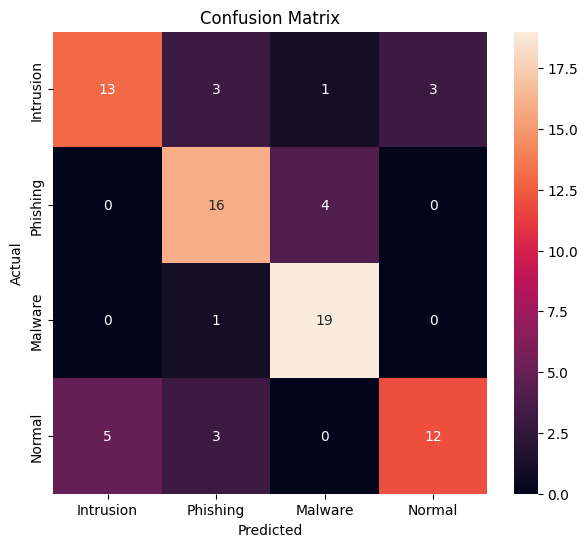

In [ ]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

with open("training_results.json") as f:
    results = json.load(f)

cm = results["confusion_matrix"]

labels = [
    "Intrusion",
    "Phishing",
    "Malware",
    "Normal"
]

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

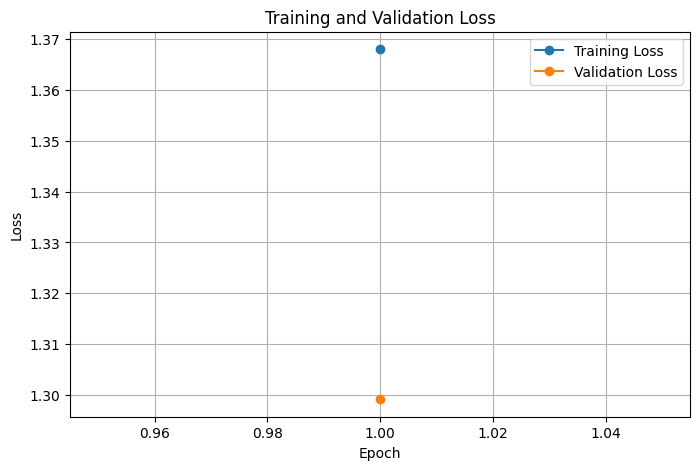

In [ ]:
import json
import matplotlib.pyplot as plt

with open("training_results.json") as f:
    results = json.load(f)

history = results["history"]

epochs = [
    x["epoch"]
    for x in history
]

train_loss = [
    x["train_loss"]
    for x in history
]

val_loss = [
    x["val_loss"]
    for x in history
]

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()